# QSVT Spectral Filtering for the Transverse-Field Ising Model

In this project I study spectral filtering with quantum singular value transformation
(QSVT) using the transverse-field Ising model (TFIM).

I start with a two-qubit example, build a block encoding of the shifted and
normalized Hamiltonian, optimize a QSP phase sequence that suppresses excited
states, and use the resulting QSVT transformation to improve the ground-state
overlap of a simple trial state. I then generalize the TFIM construction to
arbitrary system size and study the resource scaling of a Pauli/LCU
implementation.

### Roadmap

1. Start from a two-qubit TFIM.
2. Shift and normalize the spectrum.
3. Construct and verify a block encoding.
4. Build scalar QSP and optimize a spectral filter.
5. Lift the filter to matrix QSVT.
6. Apply the filter to a trial state.
7. Generalize the TFIM to arbitrary \(n\).
8. Analyze QSVT/LCU resources versus system size.


## 0. Defining Colors and Plotting Style


In [1]:
import matplotlib.pyplot as plt

COLORS = {
    "blue": "#070090",
    "green": "#3A8424",
    "red": "#8E1B11",
    "gold": "#8C6A00",
}

BLUE = COLORS["blue"]
GREEN = COLORS["green"]
RED = COLORS["red"]
GOLD = COLORS["gold"]

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    "font.size": 13,
    "axes.labelsize": 16,
    "axes.titlesize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
})


def box_axes(ax):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
    ax.grid(True, alpha=0.20)


## 1. Setup and conventions

I use the open-boundary TFIM

$$
H=-J\sum_{j=0}^{n-2} Z_jZ_{j+1}
-g\sum_{j=0}^{n-1}X_j .
$$

For Pauli strings, qubit \(0\) is the rightmost tensor factor, matching the
Qiskit convention used in Mini-project 1.


In [2]:
from __future__ import annotations

from math import ceil, log2
from numbers import Real

import numpy as np
from scipy.optimize import minimize

I = np.eye(2, dtype=complex)

X = np.array([
    [0, 1],
    [1, 0],
], dtype=complex)

Z = np.array([
    [1, 0],
    [0, -1],
], dtype=complex)


def local_operator(operator, qubit, n_qubits):
    factors = [I for _ in range(n_qubits)]
    factors[n_qubits - 1 - qubit] = operator

    result = factors[0]
    for factor in factors[1:]:
        result = np.kron(result, factor)

    return result


def tfim_hamiltonian(n_qubits, J=1.0, g=0.5):
    if n_qubits < 1:
        raise ValueError("n_qubits must be positive.")

    H = np.zeros(
        (2**n_qubits, 2**n_qubits),
        dtype=complex,
    )

    for qubit in range(n_qubits):
        H -= g * local_operator(
            X,
            qubit,
            n_qubits,
        )

    for qubit in range(n_qubits - 1):
        H -= J * (
            local_operator(Z, qubit, n_qubits)
            @ local_operator(Z, qubit + 1, n_qubits)
        )

    return H


def plus_state(n_qubits):
    return np.ones(
        2**n_qubits,
        dtype=complex,
    ) / np.sqrt(2**n_qubits)


## 2. Starting with two qubits

For $J=1$ and $g=0.5$,

$$
H=-Z_0Z_1-\frac{1}{2}(X_0+X_1).
$$

I first diagonalize this small system exactly.


In [3]:
n_qubits = 2
J = 1.0
g = 0.5

H = tfim_hamiltonian(
    n_qubits,
    J=J,
    g=g,
)

eigenvalues, eigenvectors = np.linalg.eigh(H)

print(H)
print("Eigenvalues:", eigenvalues)
print(
    "Gap:",
    eigenvalues[1] - eigenvalues[0],
)


[[-1. +0.j -0.5+0.j -0.5+0.j  0. +0.j]
 [-0.5+0.j  1. +0.j  0. +0.j -0.5+0.j]
 [-0.5+0.j  0. +0.j  1. +0.j -0.5+0.j]
 [ 0. +0.j -0.5+0.j -0.5+0.j -1. +0.j]]
Eigenvalues: [-1.41421356 -1.          1.          1.41421356]
Gap: 0.41421356237309515


## 3. Shifting and normalizing the spectrum

I shift the ground-state energy to zero and rescale the Hamiltonian into the
QSVT interval:

$$
A=\frac{H-E_0I}{\alpha},
\qquad
\alpha=1.05(E_{\max}-E_0).
$$

The factor $1.05$ keeps the largest eigenvalue slightly inside $[-1,1]$.


In [4]:
E_0 = eigenvalues[0]
E_max = eigenvalues[-1]

alpha = 1.05 * (E_max - E_0)

H_shift = (
    H
    - E_0 * np.eye(H.shape[0])
)

A = H_shift / alpha

A_eigenvalues = np.linalg.eigvalsh(A)

print("alpha =", alpha)
print("A eigenvalues =", A_eigenvalues)
print("||A|| =", np.linalg.norm(A, 2))


alpha = 2.969848480983499
A eigenvalues = [-2.89557616e-18  1.39472961e-01  8.12907991e-01  9.52380952e-01]
||A|| = 0.9523809523809526


## 4. Block encoding

For a Hermitian contraction $A$, define

$$
B=\sqrt{I-A^2}.
$$

Then

$$
W(A)=
\begin{pmatrix}
A&iB\\
iB&A
\end{pmatrix}
$$

is unitary and contains $A$ in its upper-left block.


In [5]:
eigvals_A, eigvecs_A = np.linalg.eigh(A)

B = (
    eigvecs_A
    @ np.diag(
        np.sqrt(
            np.clip(
                1 - eigvals_A**2,
                0,
                None,
            )
        )
    )
    @ eigvecs_A.conj().T
)

W = np.block([
    [A, 1j * B],
    [1j * B, A],
])

I_W = np.eye(W.shape[0])

print(
    "unitarity error =",
    np.linalg.norm(
        W.conj().T @ W - I_W
    ),
)

print(
    "block error =",
    np.linalg.norm(
        W[:4, :4] - A
    ),
)

print("shape =", W.shape)


unitarity error = 1.7405977121424584e-15
block error = 0.0
shape = (8, 8)


## 5. Scalar QSP

For a scalar $x\in[-1,1]$, the signal unitary is

$$
W(x)=
\begin{pmatrix}
x&i\sqrt{1-x^2}\\
i\sqrt{1-x^2}&x
\end{pmatrix}.
$$

With phase rotations

$$
R(\phi)=e^{i\phi Z},
$$

the QSP sequence generates a spectral response $P_\Phi(x)$.


In [6]:
def signal_unitary(x):
    if abs(x) > 1 + 1e-12:
        raise ValueError("|x| must be <= 1.")

    x = float(
        np.clip(
            x,
            -1,
            1,
        )
    )

    s = np.sqrt(
        max(
            0.0,
            1 - x**2,
        )
    )

    return np.array([
        [x, 1j * s],
        [1j * s, x],
    ], dtype=complex)


def phase_rotation(phi):
    return np.array([
        [np.exp(1j * phi), 0],
        [0, np.exp(-1j * phi)],
    ], dtype=complex)


def qsp_scalar(x, phases):
    U = phase_rotation(phases[0])
    W_x = signal_unitary(x)

    for phi in phases[1:]:
        U = (
            U
            @ W_x
            @ phase_rotation(phi)
        )

    return U


x = 0.4
test_phases = np.array([
    0.2,
    -0.3,
    0.7,
])

U_test = qsp_scalar(
    x,
    test_phases,
)

print(
    "unitarity error =",
    np.linalg.norm(
        U_test.conj().T
        @ U_test
        - np.eye(2)
    ),
)


unitarity error = 1.576947560289823e-16


## 6. Optimizing the spectral filter

The ground-state eigenvalue is at $x=0$. For even QSP degree I minimize the
response on the excited eigenvalues,

$$
\mathcal{L}(\Phi)
=
\sum_{j>0}|P_\Phi(\lambda_j)|^2.
$$

The phase optimization is classical; the QSP/QSVT sequence itself is constructed
explicitly.


In [7]:
def filter_loss(
    phases,
    excited_lambdas,
):
    return float(
        sum(
            abs(
                qsp_scalar(
                    lam,
                    phases,
                )[0, 0]
            ) ** 2
            for lam in excited_lambdas
        )
    )


def optimize_filter(
    degree,
    excited_lambdas,
    n_restarts=20,
    seed=42,
):
    rng = np.random.default_rng(seed)
    best_result = None

    for _ in range(n_restarts):
        initial_phases = rng.uniform(
            -np.pi,
            np.pi,
            degree + 1,
        )

        result = minimize(
            filter_loss,
            initial_phases,
            args=(excited_lambdas,),
            method="BFGS",
        )

        if (
            best_result is None
            or result.fun < best_result.fun
        ):
            best_result = result

    return best_result


degrees = [2, 4, 6, 8]
lambdas = np.linalg.eigvalsh(A)

filter_results = {}

for degree in degrees:
    result = optimize_filter(
        degree,
        lambdas[1:],
    )

    filter_results[degree] = result

    print(
        f"\ndegree = {degree}, "
        f"loss = {result.fun:.6f}"
    )

    for lam in lambdas:
        response = qsp_scalar(
            lam,
            result.x,
        )[0, 0]

        print(
            f"x = {lam:.6f}, "
            f"|P(x)| = {abs(response):.6f}"
        )



degree = 2, loss = 1.689846
x = -0.000000, |P(x)| = 1.000000
x = 0.139473, |P(x)| = 0.961095
x = 0.812908, |P(x)| = 0.321639
x = 0.952381, |P(x)| = 0.814059

degree = 4, loss = 1.141100
x = -0.000000, |P(x)| = 1.000000
x = 0.139473, |P(x)| = 0.891746
x = 0.812908, |P(x)| = 0.272060
x = 0.952381, |P(x)| = 0.521414

degree = 6, loss = 0.535750
x = -0.000000, |P(x)| = 1.000000
x = 0.139473, |P(x)| = 0.705358
x = 0.812908, |P(x)| = 0.132907
x = 0.952381, |P(x)| = 0.143375

degree = 8, loss = 0.296394
x = -0.000000, |P(x)| = 1.000000
x = 0.139473, |P(x)| = 0.536276
x = 0.812908, |P(x)| = 0.058217
x = 0.952381, |P(x)| = 0.073575


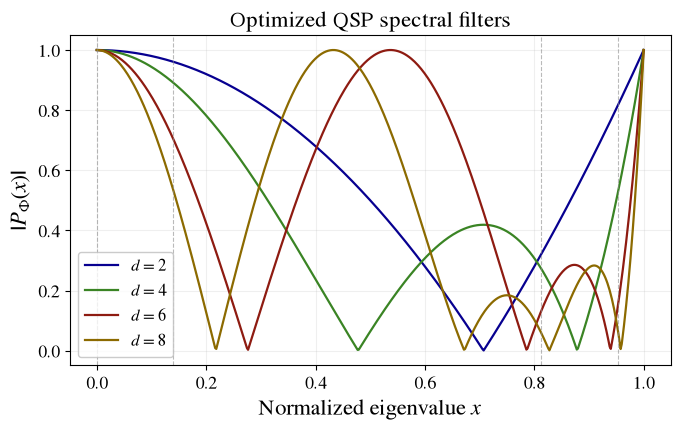

In [8]:
x_grid = np.linspace(
    0,
    1,
    500,
)

colors = {
    2: BLUE,
    4: GREEN,
    6: RED,
    8: GOLD,
}

plt.figure(figsize=(7, 4.5))

for degree in degrees:
    phases = filter_results[degree].x

    response = [
        abs(
            qsp_scalar(
                x,
                phases,
            )[0, 0]
        )
        for x in x_grid
    ]

    plt.plot(
        x_grid,
        response,
        color=colors[degree],
        linewidth=1.6,
        label=rf"$d={degree}$",
    )

for lam in lambdas:
    plt.axvline(
        lam,
        color="0.55",
        linestyle="--",
        linewidth=0.8,
        alpha=0.6,
    )

plt.xlabel(r"Normalized eigenvalue $x$")
plt.ylabel(r"$|P_\Phi(x)|$")
plt.title("Optimized QSP spectral filters")

plt.legend(
    frameon=True,
    facecolor="white",
    edgecolor="0.75",
)

ax = plt.gca()
box_axes(ax)

plt.tight_layout()
plt.show()


## 7. Lifting QSP to QSVT

The scalar phase sequence is applied to the full block encoding by replacing
\(W(x)\) with \(W(A)\). I compare the selected block with the independently
evaluated spectral function \(P_\Phi(A)\).


In [9]:
def matrix_phase_rotation(
    phi,
    system_dim,
):
    return np.kron(
        phase_rotation(phi),
        np.eye(
            system_dim,
            dtype=complex,
        ),
    )


def qsvt_matrix(
    W,
    phases,
    system_dim,
):
    U = matrix_phase_rotation(
        phases[0],
        system_dim,
    )

    for phi in phases[1:]:
        U = (
            U
            @ W
            @ matrix_phase_rotation(
                phi,
                system_dim,
            )
        )

    return U


phases_8 = filter_results[8].x

U_qsvt = qsvt_matrix(
    W,
    phases_8,
    system_dim=4,
)

filtered_block = U_qsvt[:4, :4]

responses = np.array([
    qsp_scalar(
        lam,
        phases_8,
    )[0, 0]
    for lam in eigvals_A
])

P_of_A = (
    eigvecs_A
    @ np.diag(responses)
    @ eigvecs_A.conj().T
)

print(
    "QSVT block error =",
    np.linalg.norm(
        filtered_block - P_of_A
    ),
)


QSVT block error = 3.3947619305932408e-15


## 8. Filtering a trial state

I use

$$
|\psi\rangle=|++\rangle.
$$

After postselecting the signal ancilla, the filtered state is proportional to

$$
P_\Phi(A)|\psi\rangle.
$$

I compare ground-state fidelity and postselection probability as the QSVT degree
increases.


In [10]:
ground_state = eigenvectors[:, 0]

plus = np.array(
    [1.0, 1.0]
) / np.sqrt(2)

psi = np.kron(
    plus,
    plus,
)

initial_fidelity = abs(
    np.vdot(
        ground_state,
        psi,
    )
) ** 2

fidelities = []
success_probabilities = []

print(
    "initial ground-state fidelity =",
    initial_fidelity,
)

for degree in degrees:
    phases = filter_results[degree].x

    U_qsvt = qsvt_matrix(
        W,
        phases,
        system_dim=4,
    )

    block = U_qsvt[:4, :4]

    unnormalized = (
        block
        @ psi
    )

    success = (
        np.linalg.norm(
            unnormalized
        ) ** 2
    )

    filtered_state = (
        unnormalized
        / np.sqrt(success)
    )

    fidelity = abs(
        np.vdot(
            ground_state,
            filtered_state,
        )
    ) ** 2

    success_probabilities.append(
        success
    )
    fidelities.append(
        fidelity
    )

    print(
        f"degree = {degree}, "
        f"success = {success:.6f}, "
        f"ground fidelity = {fidelity:.6f}"
    )


initial ground-state fidelity = 0.853553390593273
degree = 2, success = 0.950602, ground fidelity = 0.897908
degree = 4, success = 0.893368, ground fidelity = 0.955433
degree = 6, success = 0.856564, ground fidelity = 0.996485
degree = 8, success = 0.854346, ground fidelity = 0.999072


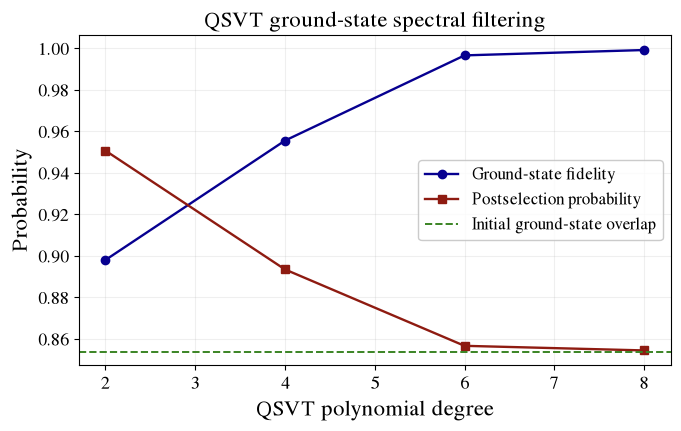

In [11]:
plt.figure(figsize=(7, 4.5))

plt.plot(
    degrees,
    fidelities,
    marker="o",
    color=BLUE,
    linewidth=1.7,
    markersize=6,
    label="Ground-state fidelity",
)

plt.plot(
    degrees,
    success_probabilities,
    marker="s",
    color=RED,
    linewidth=1.7,
    markersize=6,
    label="Postselection probability",
)

plt.axhline(
    initial_fidelity,
    color=GREEN,
    linestyle="--",
    linewidth=1.4,
    label="Initial ground-state overlap",
)

plt.xlabel("QSVT polynomial degree")
plt.ylabel("Probability")
plt.title("QSVT ground-state spectral filtering")

plt.legend(
    frameon=True,
    facecolor="white",
    edgecolor="0.75",
)

ax = plt.gca()
box_axes(ax)

plt.tight_layout()
plt.show()


The success probability approaches the initial ground-state overlap as the filter
becomes more projector-like, while the conditional ground-state fidelity approaches
one.


## 9. Generalizing to arbitrary TFIM size

The dense construction above works for arbitrary \(n\), although exact
diagonalization and the dense block encoding become exponentially expensive.
I use \(n=2,3,4\) for exact numerical checks and keep the large-\(n\) analysis at
the Pauli/LCU resource level.


In [12]:
def qsvt_instance(
    n_qubits,
    J=1.0,
    g=0.5,
    safety_factor=1.05,
):
    H = tfim_hamiltonian(
        n_qubits,
        J=J,
        g=g,
    )

    energies, eigenvectors = np.linalg.eigh(H)

    E_0 = energies[0]
    alpha = (
        safety_factor
        * (energies[-1] - E_0)
    )

    A = (
        H
        - E_0 * np.eye(H.shape[0])
    ) / alpha

    lambdas, eigvecs_A = np.linalg.eigh(A)

    return {
        "H": H,
        "energies": energies,
        "eigenvectors": eigenvectors,
        "A": A,
        "lambdas": lambdas,
        "eigvecs_A": eigvecs_A,
        "gap": energies[1] - energies[0],
        "normalized_gap": (
            lambdas[1] - lambdas[0]
        ),
    }


def filter_instance(
    n_qubits,
    degrees,
    J=1.0,
    g=0.5,
):
    data = qsvt_instance(
        n_qubits,
        J=J,
        g=g,
    )

    W = block_encoding(
        data["A"]
    )

    psi = plus_state(
        n_qubits
    )

    ground_state = (
        data["eigenvectors"][:, 0]
    )

    initial_fidelity = abs(
        np.vdot(
            ground_state,
            psi,
        )
    ) ** 2

    results = {
        "initial_fidelity": initial_fidelity,
        "fidelities": [],
        "success": [],
        "gap": data["gap"],
        "normalized_gap": data["normalized_gap"],
    }

    for degree in degrees:
        result = optimize_filter(
            degree,
            data["lambdas"][1:],
            n_restarts=10,
            seed=42,
        )

        U_qsvt = qsvt_matrix(
            W,
            result.x,
            system_dim=2**n_qubits,
        )

        block = U_qsvt[
            : 2**n_qubits,
            : 2**n_qubits,
        ]

        unnormalized = (
            block
            @ psi
        )

        success = (
            np.linalg.norm(
                unnormalized
            ) ** 2
        )

        filtered = (
            unnormalized
            / np.sqrt(success)
        )

        fidelity = abs(
            np.vdot(
                ground_state,
                filtered,
            )
        ) ** 2

        results["fidelities"].append(
            fidelity
        )
        results["success"].append(
            success
        )

    return results


def block_encoding(A):
    eigvals, eigvecs = np.linalg.eigh(A)

    B = (
        eigvecs
        @ np.diag(
            np.sqrt(
                np.clip(
                    1 - eigvals**2,
                    0,
                    None,
                )
            )
        )
        @ eigvecs.conj().T
    )

    return np.block([
        [A, 1j * B],
        [1j * B, A],
    ])


In [13]:
size_results = {}

for n_qubits in [2, 3, 4]:
    result = filter_instance(
        n_qubits,
        degrees,
        J=1.0,
        g=0.5,
    )

    size_results[n_qubits] = result

    print(
        f"n = {n_qubits}, "
        f"gap = {result['gap']:.6f}, "
        f"normalized gap = "
        f"{result['normalized_gap']:.6f}"
    )

    for degree, fidelity in zip(
        degrees,
        result["fidelities"],
    ):
        print(
            f"  degree {degree}: "
            f"fidelity = {fidelity:.6f}"
        )


n = 2, gap = 0.414214, normalized gap = 0.139473
  degree 2: fidelity = 0.897908
  degree 4: fidelity = 0.955433
  degree 6: fidelity = 0.996485
  degree 8: fidelity = 0.999072
n = 3, gap = 0.193937, normalized gap = 0.038428
  degree 2: fidelity = 0.820467
  degree 4: fidelity = 0.988651
  degree 6: fidelity = 0.995398
  degree 8: fidelity = 0.997535
n = 4, gap = 0.094788, normalized gap = 0.013171
  degree 2: fidelity = 0.626518
  degree 4: fidelity = 0.735615
  degree 6: fidelity = 0.849633
  degree 8: fidelity = 0.920582


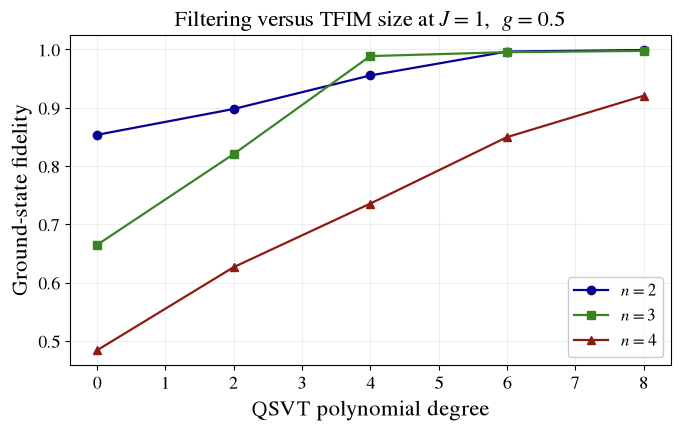

In [14]:
plt.figure(figsize=(7, 4.5))

size_colors = {
    2: BLUE,
    3: GREEN,
    4: RED,
}

markers = {
    2: "o",
    3: "s",
    4: "^",
}

for n_qubits in [2, 3, 4]:
    result = size_results[n_qubits]

    x_values = [0] + degrees
    y_values = (
        [result["initial_fidelity"]]
        + result["fidelities"]
    )

    plt.plot(
        x_values,
        y_values,
        marker=markers[n_qubits],
        color=size_colors[n_qubits],
        linewidth=1.6,
        markersize=6,
        label=rf"$n={n_qubits}$",
    )

plt.xlabel("QSVT polynomial degree")
plt.ylabel("Ground-state fidelity")
plt.title(
    r"Filtering versus TFIM size "
    r"at $J=1,\ g=0.5$"
)

plt.legend(
    frameon=True,
    facecolor="white",
    edgecolor="0.75",
)

ax = plt.gca()
box_axes(ax)

plt.tight_layout()
plt.show()


## 10. Resource analysis

For an open $n$-qubit TFIM there are $2n-1$ nonidentity Pauli terms. Shifting
by a target energy adds one identity term, so the shifted Hamiltonian has $2n$
LCU terms.

A term-label register therefore needs

$$
\left\lceil\log_2(2n)\right\rceil
$$

ancilla qubits. A degree-$d$ QSVT sequence uses $d$ block-encoding queries.
At the logical SELECT level, a straightforward implementation therefore scales as
$O(dn)$.


In [15]:
def tfim_pauli_terms(
    n_qubits,
    J=1.0,
    g=0.5,
    energy_shift=None,
):
    terms = {}

    for qubit in range(n_qubits):
        pauli = ["I"] * n_qubits
        pauli[n_qubits - 1 - qubit] = "X"
        terms["".join(pauli)] = -g

    for qubit in range(n_qubits - 1):
        pauli = ["I"] * n_qubits
        pauli[n_qubits - 1 - qubit] = "Z"
        pauli[
            n_qubits - 1 - (qubit + 1)
        ] = "Z"

        terms["".join(pauli)] = -J

    if energy_shift is not None:
        terms["I" * n_qubits] = -energy_shift

    return terms


def lcu_resource_summary(
    n_qubits,
    degree,
):
    n_terms = 2 * n_qubits

    return {
        "n_qubits": n_qubits,
        "degree": degree,
        "terms": n_terms,
        "label_ancillas": ceil(
            log2(n_terms)
        ),
        "block_queries": degree,
        "select_branches": (
            degree * n_terms
        ),
    }


terms_3 = tfim_pauli_terms(
    n_qubits=3,
    J=1.0,
    g=0.5,
    energy_shift=-1.2,
)

print(terms_3)

print(
    lcu_resource_summary(
        n_qubits=3,
        degree=8,
    )
)


{'IIX': -0.5, 'IXI': -0.5, 'XII': -0.5, 'IZZ': -1.0, 'ZZI': -1.0, 'III': 1.2}
{'n_qubits': 3, 'degree': 8, 'terms': 6, 'label_ancillas': 3, 'block_queries': 8, 'select_branches': 48}


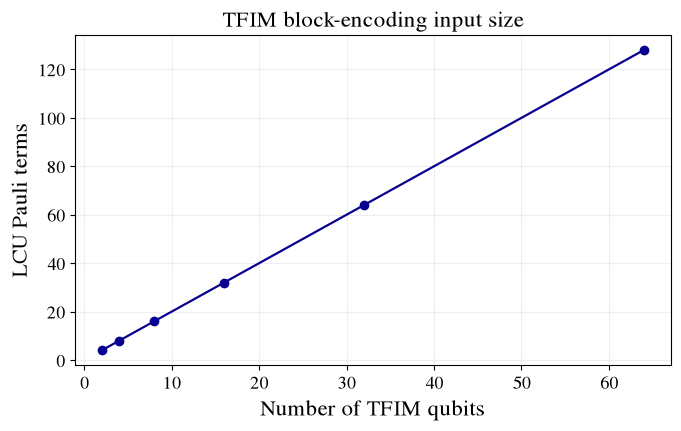

In [16]:
n_values = np.array([
    2,
    4,
    8,
    16,
    32,
    64,
])

term_counts = 2 * n_values

plt.figure(figsize=(7, 4.5))

plt.plot(
    n_values,
    term_counts,
    marker="o",
    color=BLUE,
    linewidth=1.6,
    markersize=6,
)

plt.xlabel("Number of TFIM qubits")
plt.ylabel("LCU Pauli terms")
plt.title("TFIM block-encoding input size")

ax = plt.gca()
box_axes(ax)

plt.tight_layout()
plt.show()


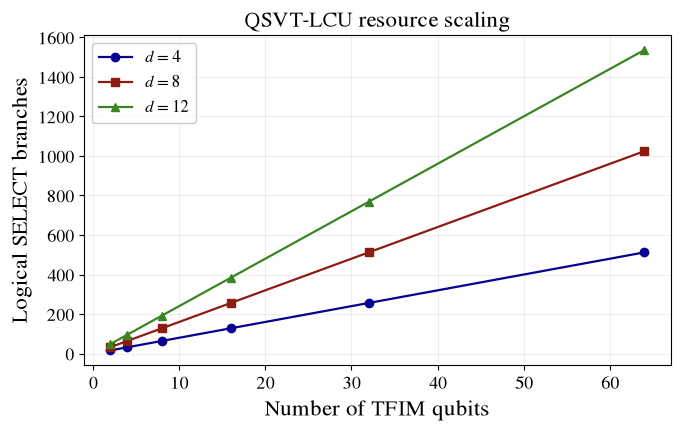

In [17]:
plt.figure(figsize=(7, 4.5))

resource_degrees = [
    4,
    8,
    12,
]

resource_colors = {
    4: BLUE,
    8: RED,
    12: GREEN,
}

markers = {
    4: "o",
    8: "s",
    12: "^",
}

for degree in resource_degrees:
    select_branches = (
        degree
        * term_counts
    )

    plt.plot(
        n_values,
        select_branches,
        marker=markers[degree],
        color=resource_colors[degree],
        linewidth=1.6,
        markersize=6,
        label=rf"$d={degree}$",
    )

plt.xlabel("Number of TFIM qubits")
plt.ylabel("Logical SELECT branches")
plt.title("QSVT-LCU resource scaling")

plt.legend(
    frameon=True,
    facecolor="white",
    edgecolor="0.75",
)

ax = plt.gca()
box_axes(ax)

plt.tight_layout()
plt.show()


The dense matrix code is useful for checking the construction on small systems,
but it is not the scalable representation. The TFIM itself has only $O(n)$ Pauli
terms, while a degree-$d$ QSVT sequence makes $O(d)$ block-encoding queries.

## 11. Conclusions

The two-qubit example verifies the full chain

$$
H
\rightarrow
A
\rightarrow
W(A)
\rightarrow
P_\Phi(A)
\rightarrow
|\psi_{\mathrm{filtered}}\rangle.
$$

Increasing QSVT degree improves the ground-state filter. The small-$n$ extension
shows how the finite-size gap affects the filtering problem, while the Pauli/LCU
description gives the relevant large-$n$ resource scaling.

### Reference

A. Gilyén, Y. Su, G. H. Low, and N. Wiebe, *Quantum singular value
transformation and beyond: exponential improvements for quantum matrix
arithmetics*, arXiv:1806.01838.
